# Ghép ảnh panorama bằng pipeline C++ tuần tự

**Nhóm 09**

Ghép ảnh panorama ước lượng quan hệ hình học giữa hai ảnh có vùng chồng lấp, đưa
chúng về cùng hệ tọa độ và trộn màu để tạo ảnh toàn cảnh. Phiên bản V0 thực hiện
sáu giai đoạn trên một luồng CPU. Độ chính xác homography, chất lượng vùng nối và
thời gian từng giai đoạn được đánh giá riêng để xác định phạm vi tăng tốc CUDA.

## 1. Bài toán, phương pháp và phân công

**Đầu vào:** hai ảnh màu A và B có vùng chồng lấp. **Đầu ra:** panorama, homography
B→A, tập cặp điểm khớp/inlier và thời gian xử lý. Homography là ma trận 3×3 xác định
đến một hệ số tỷ lệ; với điểm ảnh đồng nhất, quan hệ chiếu có dạng

$$s\begin{bmatrix}x_A\\y_A\\1\end{bmatrix}
=H_{B\to A}\begin{bmatrix}x_B\\y_B\\1\end{bmatrix}.$$

Một homography phù hợp khi cảnh gần phẳng hoặc máy ảnh chủ yếu xoay quanh cùng
vị trí. Vật chuyển động, chênh lệch chiều sâu và thay đổi phơi sáng có thể tạo vùng
nối hoặc bóng đôi ngay cả khi ước lượng hình học thành công.

**Luồng xử lý:** ảnh A/B → S1 điểm đặc trưng → S2 descriptor → S3 cặp khớp →
S4 homography B→A → S5 hai ảnh trên cùng canvas → S6 panorama.

| Giai đoạn | Phương pháp và tham số | Chất lượng và khả năng song song |
|---|---|---|
| S1 — phát hiện điểm | FAST-9, ngưỡng 20; Harris/NMS; tháp 8 mức, tỷ lệ 1,2; tối đa 2.000 điểm mỗi ảnh | Tháp ảnh tăng khả năng chịu thay đổi tỷ lệ. Tính điểm theo pixel phù hợp GPU; NMS và gom điểm cần xử lý phụ thuộc. |
| S2 — mô tả điểm | Hướng intensity-centroid; rotated BRIEF 256 bit | Xét góc xoay và dùng descriptor gọn. Mỗi keypoint có thể được xử lý độc lập. |
| S3 — matching | Hamming vét cạn; ratio 0,8; không cross-check | Ratio loại cặp mơ hồ nhưng không loại được mọi outlier. Các khoảng cách descriptor độc lập, phù hợp chia theo thread/warp. |
| S4 — homography | DLT chuẩn hóa; RANSAC 2.000 vòng, seed cố định; ngưỡng 3 px tại rộng 800 px | Chuẩn hóa giúp ổn định số; RANSAC giảm ảnh hưởng outlier. Giữ trên CPU trong phương án đầu để đối chiếu nghiệm và lựa chọn inlier. |
| S5 — warping | Canvas từ các góc ảnh; inverse mapping; nội suy song tuyến tính | Ánh xạ ngược hạn chế lỗ ảnh. Các pixel đích độc lập; cần thống nhất cách xử lý biên. |
| S6 — blending | Feather theo khoảng cách đến biên mask | Làm mềm chuyển tiếp màu, nhưng không khử hết bóng đôi. Bước trộn theo pixel song song được; distance map có phụ thuộc riêng. |

V0 dùng C++17, không dùng OpenMP, `std::thread`, SIMD tự viết hoặc thư viện
stitching. S1/S2 được tính cho cả hai ảnh. Python hỗ trợ đọc/ghi ảnh, biên dịch và
thống kê; thuật toán S1–S6 nằm trong `src/`. `main.cu` hiện điều phối V0 CPU.
Pattern BRIEF được cài đặt độc lập, chưa xác nhận tương thích từng bit với OpenCV ORB.

| Thành viên | Phụ trách V0 | Phụ trách V1 dự kiến | Hướng tối ưu V2 dự kiến |
|---|---|---|---|
| 23120318 — TRƯƠNG QUANG PHÁT | S1–S2 | Đối chiếu đặc trưng; xem xét S1 theo profiling | Tháp ảnh, FAST/Harris, NMS và gom keypoint |
| 23120329 — CHÂU HUỲNH PHÚC | S3–S4 | CUDA S3; giữ S4 CPU để đối chiếu | Tile descriptor và warp reduction |
| 23120334 — HUỲNH TẤN PHƯỚC | S5–S6, tích hợp | CUDA S5–S6; tích hợp pipeline | Tái dùng buffer, truy cập liên tiếp, giảm sao chép |


In [1]:
# @title Thiết lập môi trường thực nghiệm
from pathlib import Path
import importlib.util, os, stat, subprocess, sys, zipfile
root = Path.cwd().resolve()
if not (root / "src/notebook_support.py").is_file():
    archive = Path("Group09_Midterm.zip")
    if not archive.is_file():
        raise FileNotFoundError(
            "Thiếu Group09_Midterm.zip trong /content. Mở Files > Upload, "
            "tải ZIP vào /content rồi chạy lại ô thiết lập."
        )
    root = root / "cuda-image-stitching"
    root.mkdir(exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        if z.testzip() is not None:
            raise ValueError("ZIP bị lỗi CRC")
        for e in z.infolist():
            if not (root/e.filename).resolve().is_relative_to(root.resolve()) or stat.S_ISLNK(e.external_attr >> 16):
                raise ValueError("Đường dẫn ZIP không an toàn")
            if not (e.filename.startswith("src/") or e.filename == "Group09_Midterm.ipynb"):
                raise ValueError("ZIP không đúng cấu trúc dự án")
        z.extractall(root)
packages = {"PIL":"Pillow","pandas":"pandas","matplotlib":"matplotlib"}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.run([sys.executable,"-m","pip","install","-q",*missing],check=True)
sys.path.insert(0,str(root/"src"))
import notebook_support as report
report.configure(root)
report.run("setup",report.prepare)

Dataset: SHA-256 của ZIP hợp lệ.
V0: biên dịch C++17 hoàn tất, sử dụng một luồng CPU.
Môi trường: Windows / wsl; g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0.


## 2. Dữ liệu và cách chuẩn bị

[Bộ dữ liệu đã chuẩn bị — ảnh gốc, các cặp ảnh và metadata](https://drive.google.com/file/d/11Nbg77zkOizdNcY5vEmlybP60KTv5NUk/view)
được xây dựng từ [ảnh OpenPano CMU](https://github.com/ppwwyyxx/OpenPano/releases/tag/0.1).
CMU0, CMU1 và CMU2 là các nhãn bộ ảnh theo nguồn; trạng thái tương ứng với các site
nhóm đã đăng ký chưa được xác nhận.

Các cặp chuẩn đại diện cho từng bộ ảnh; cặp CMU0 khó bổ sung trường hợp vùng nối
phức tạp. Danh sách ảnh cụ thể được lưu tại `dataset/metadata.csv`. Ảnh được resize
giữ tỷ lệ bằng LANCZOS, theo chiều rộng 400, 800 và 1.200 px, sau đó lưu JPEG chất
lượng 95. Hai ảnh của mỗi cặp giữ cùng quy trình chuẩn bị.

Thư mục `dataset/raw/` chứa ảnh gốc; `dataset/prepared/` chứa ảnh dùng trong phép đo.
ZIP trên Drive cung cấp dữ liệu đã chuẩn bị; liên kết OpenPano ghi nguồn gốc ảnh.
ZIP dữ liệu được đối chiếu SHA-256 trước khi giải nén. Các đường dẫn được tính
từ thư mục dự án.


In [2]:
# @title Các cặp ảnh và kích thước
report.ensure_dataset()
report.run("dataset",report.dataset)

Cặp ảnh,Ảnh A,Ảnh B,Kích thước gốc A/B
CMU0 — chuẩn,dataset/raw/CMU0/medium03.JPG,dataset/raw/CMU0/medium04.JPG,1300x867 / 1300x867
CMU0 — khó,dataset/raw/CMU0/medium23.JPG,dataset/raw/CMU0/medium24.JPG,1300x867 / 1300x867
CMU1 — chuẩn,dataset/raw/CMU1/medium09.jpg,dataset/raw/CMU1/medium10.jpg,1500x1112 / 1500x1112
CMU2 — chuẩn,dataset/raw/CMU2/medium04.JPG,dataset/raw/CMU2/medium05.JPG,1300x867 / 1300x867


resolution,Bộ ảnh,Nhỏ (400 px),Vừa (800 px),Lớn (1.200 px)
,CMU0,400x267,800x534,1200x800
,CMU1,400x297,800x593,1200x890
,CMU2,400x267,800x534,1200x800


## 3. Độ chính xác hình học

Ảnh tổng hợp có cấu trúc và texture được biến đổi bằng homography đã biết, tạo bốn
trường hợp: tịnh tiến, xoay, đổi tỷ lệ và phối cảnh. H ước lượng được đối chiếu với
H chuẩn trên 48 điểm lưới độc lập với tập inlier dùng để khớp mô hình.

Với $\pi$ là phép chia tọa độ đồng nhất, sai số của điểm kiểm tra $q_i$ được tính bằng

$$e_i=\left\|\pi(\widehat H q_i)-\pi(H_{\mathrm{chuẩn}}q_i)\right\|_2.$$

Sai số trung bình và lớn nhất có đơn vị pixel. Ngưỡng kiểm tra nội bộ là trung bình
nhỏ hơn 3 px và lớn nhất nhỏ hơn 6 px. Kết quả chỉ phản ánh bốn phép biến đổi tổng
hợp; không suy ra độ chính xác của mọi cảnh thực tế.


In [3]:
# @title Sai số homography trên ảnh tổng hợp
report.run("correctness",report.correctness)

Đạt 4/4 phép thử. Sai số lớn nhất: 1.82 px; chưa kết luận độ đúng của mọi ảnh thực tế.


Phép biến đổi,Sai số TB (px),Sai số lớn nhất (px)
Tịnh tiến,0.000,0.000
Xoay,0.099,0.169
Đổi tỷ lệ,0.804,1.817
Phối cảnh,0.494,1.222


## 4. Hiệu năng V0

Bốn cặp ảnh, ba kích thước và hai chế độ blending tạo 24 cấu hình. Mỗi cấu hình có
một lượt làm nóng không tính vào thống kê, sau đó ba lượt đo, tổng cộng 72 lượt đo.
Thời gian được lấy bằng `std::chrono::steady_clock` trong chương trình C++.

**Phạm vi đo:** chuyển RGB sang ảnh xám và S1–S6. S1/S2 là tổng công việc trên cả
hai ảnh. Đọc/ghi tệp, giải mã JPEG, biên dịch và khởi tạo tiến trình nằm ngoài phạm
vi này. Vì vậy, thời gian pipeline không phải thời gian toàn bộ phiên thực nghiệm.

Bảng và biểu đồ chính dùng feather làm mốc; mỗi giá trị là trung bình của bốn cặp
ảnh tại cùng kích thước. Bảng chi tiết ghi kết quả từng cặp và độ lệch chuẩn của
ba lượt đo. Số liệu phụ thuộc CPU, trình biên dịch và môi trường được ghi kèm.


Đơn vị: ms. Mỗi dòng là trung bình của bốn cặp ảnh; baseline feather.
• Nhỏ (400 px): S3 chiếm 65.3% tổng thời gian.
• Vừa (800 px): S3 chiếm 44.8% tổng thời gian.
• Lớn (1.200 px): S1 chiếm 35.7% tổng thời gian.


Thông tin môi trường,Giá trị
CPU,12th Gen Intel(R) Core(TM) i5-12500H
Nền tảng / backend,Windows-11-10.0.26200-SP0 / wsl
Trình biên dịch,g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Cờ biên dịch,-std=c++17 -Wall -Wextra -Wpedantic -Werror -O2 -Isrc -DSTITCHING_NO_MAIN -x c++
Lặp đo / làm nóng mỗi cấu hình,3 / 1


Kích thước,S1,S2,S3,S4,S5,S6,Tổng,Chậm nhất
Nhỏ (400 px),33.6,35.3,276.3,53.0,11.9,12.6,423.1,S3
Vừa (800 px),161.4,62.8,300.8,52.4,46.0,45.8,671.0,S3
Lớn (1.200 px),381.9,104.9,310.9,48.6,104.0,116.5,1070.9,S1


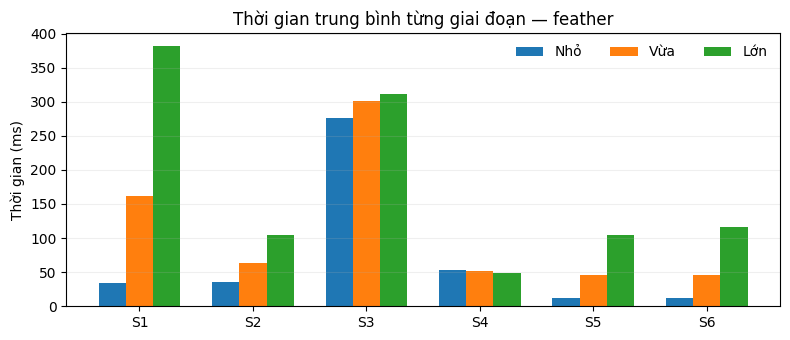

Cặp ảnh,Kích thước,Cách trộn,s1_ms,s2_ms,s3_ms,s4_ms,s5_ms,s6_ms,Tổng (ms),ĐLC tổng (ms)
cmu0_standard,small,feather,32.91,37.34,308.66,58.03,9.04,10.69,457.33,20.23
cmu0_standard,small,seam,34.97,37.09,299.91,55.41,8.76,5.46,442.05,17.26
cmu0_standard,medium,feather,166.11,59.26,307.88,60.75,34.29,35.95,665.88,7.91
cmu0_standard,medium,seam,170.77,63.31,323.70,66.78,33.47,22.90,682.68,22.75
cmu0_standard,large,feather,391.94,100.59,312.61,57.16,73.22,82.10,1021.54,13.95
cmu0_standard,large,seam,400.54,100.87,320.02,55.65,79.03,51.96,1011.82,25.67
cmu0_challenging,small,feather,33.28,38.02,316.50,59.22,15.41,15.66,478.60,4.00
cmu0_challenging,small,seam,35.24,36.96,318.62,59.05,14.85,7.85,472.95,5.61
cmu0_challenging,medium,feather,163.21,68.67,313.43,52.99,60.43,60.54,720.93,16.93
cmu0_challenging,medium,seam,165.63,66.46,327.91,54.52,65.31,35.75,717.83,45.07


In [4]:
# @title Môi trường đo, thời gian từng giai đoạn và nút thắt
report.run("profiling",report.profiling)

## 5. Chất lượng panorama

Các panorama đại diện dùng feather với ảnh đầu vào rộng 800 px. Cạnh công trình,
vùng chồng lấp và các vật thể gần là các vị trí quan sát độ liên tục hình học.
Sự thay đổi độ sáng và bóng đôi được xem xét riêng với khả năng tìm điểm khớp.

Tỷ lệ inlier là số cặp được RANSAC giữ lại chia cho số cặp khớp. Sai số inlier là
sai số chiếu trên chính tập đó; đây không phải sai số so với panorama chuẩn và
không bảo đảm toàn bộ vùng nối đã chính xác.

Vùng đen ngoài miền phủ của hai ảnh là phần canvas không có dữ liệu ảnh. Canvas
được giữ nguyên để quan sát hình học sau phép chiếu; kết quả chưa tự cắt bỏ biên đen.


Ảnh ở chiều rộng đầu vào 800 px. Sai số inlier chỉ đo trên các cặp được RANSAC giữ lại, không phải sai số so với ảnh chuẩn.


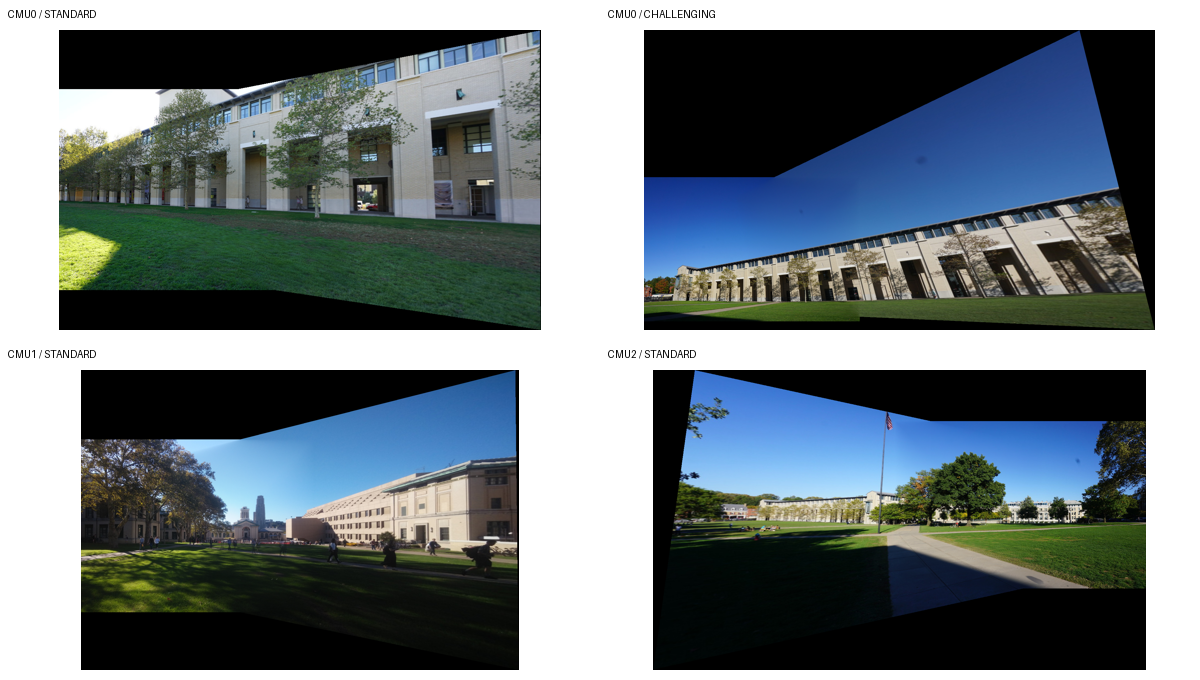

Cặp ảnh,Cặp khớp,Inlier,Tỷ lệ inlier,Sai số inlier (px)
CMU0 — chuẩn,431,375,87.0%,1.20
CMU0 — khó,430,306,71.2%,1.12
CMU1 — chuẩn,264,218,82.6%,1.19
CMU2 — chuẩn,482,414,85.9%,1.13


In [5]:
# @title Panorama và thống kê inlier
report.run("panoramas",report.panoramas)

Cặp CMU0 khó còn chênh sáng ở vùng trời; CMU2 có dải chuyển sáng trong vùng chồng
lấp. Các hiện tượng này cho thấy matching thành công và ảnh ghép liền mạch là hai
khía cạnh cần được đánh giá riêng.

### 5.1. So sánh feather và seam

Phương án bổ sung tìm đường nối có sai khác thấp, áp dụng feather bán kính 8 px và
bù sáng RGB giới hạn 0,5–2. Thời gian so sánh là tổng thời gian pipeline với cùng
cặp ảnh và kích thước. Trường hợp seam không áp dụng được sử dụng feather dự phòng;
số trường hợp dự phòng được ghi trong kết quả.

Hai ảnh trên cặp khó cho phép quan sát ảnh hưởng của đường nối và bù sáng. Một
homography không mô tả được mọi parallax hoặc chuyển động; seam cũng không bảo đảm
loại bỏ hoàn toàn bóng đôi. Feather tiếp tục là cấu hình tham chiếu CPU/GPU.


Seam không áp dụng được ở 0/12 cấu hình (các trường hợp đó dùng feather).
Chọn feather làm mốc CPU/GPU. Seam là phép so sánh bổ sung; vẫn có thể còn bóng đôi do chuyển động hoặc parallax.


Kích thước,Feather (ms),Seam (ms)
Nhỏ (400 px),423.1,414.6
Vừa (800 px),671.0,668.3
Lớn (1.200 px),1070.9,1007.2



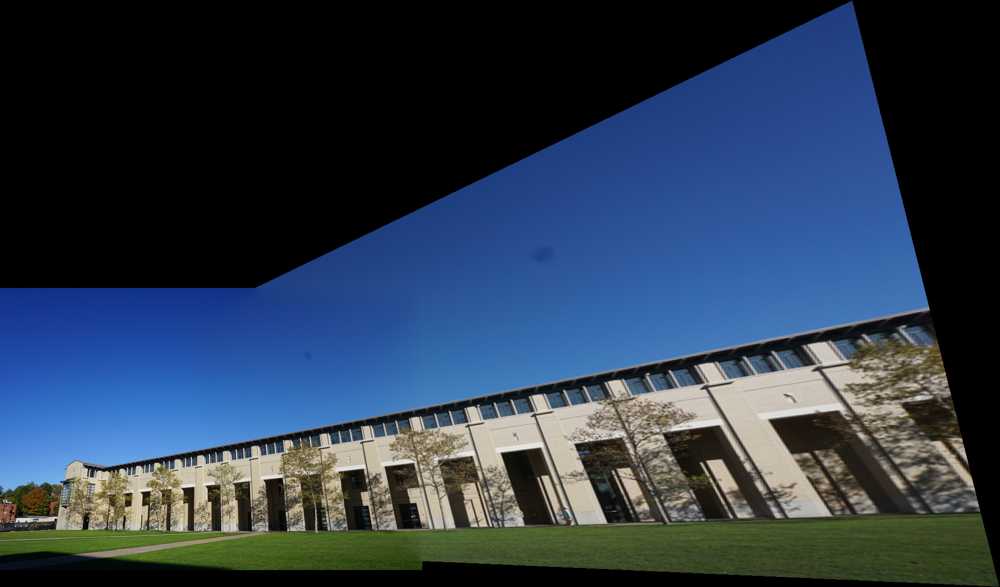
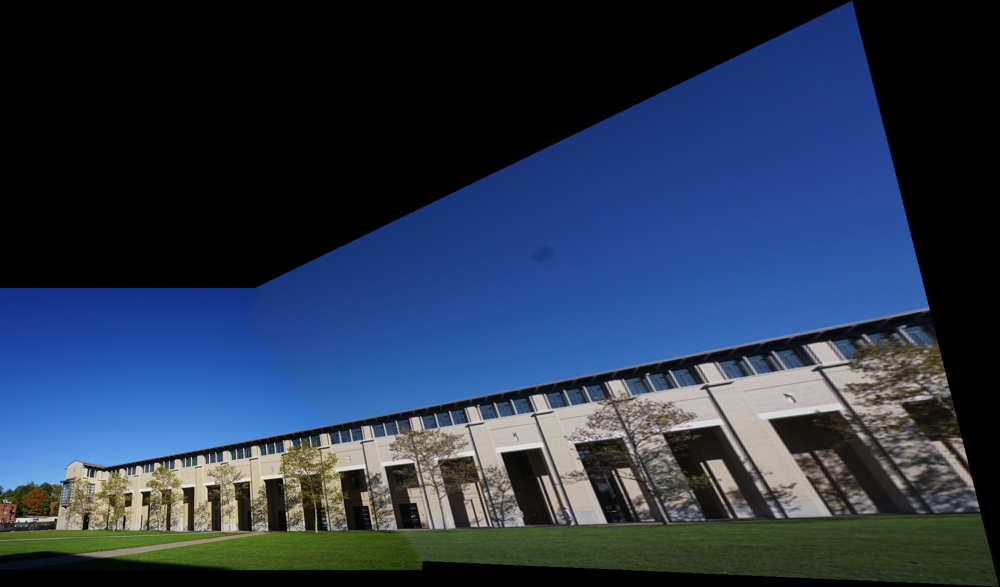

In [6]:
# @title Đối chiếu feather và seam
report.run("comparison",report.comparison)

## 6. Kế hoạch tăng tốc CUDA

S3, S5 và S6 là phạm vi V1 dự kiến: matching có nhiều khoảng cách descriptor độc
lập, còn warping và trộn màu có thể phân chia theo pixel đích. Mức ưu tiên cần xét
cùng tỷ trọng thời gian theo kích thước ảnh. S1 là phần mở rộng cần cân nhắc khi
chi phí phát hiện điểm tăng ở ảnh lớn.

| Phần | Ánh xạ V1 dự kiến | Hướng tối ưu V2 | Rủi ro cần đối chiếu |
|---|---|---|---|
| S3 | Thread/warp tính khoảng cách descriptor; reduction lấy hai láng giềng | Đọc liên tiếp, tile descriptor, warp reduction | Phá hòa khoảng cách, bộ nhớ tạm, truyền dữ liệu |
| S5 | Grid 2D; mỗi thread tính một pixel đích | H trong constant memory, cache/texture, ghi liên tiếp | Biên ảnh, sai số nội suy, canvas lớn |
| S6 | Mỗi thread trộn một pixel; distance map xử lý riêng | Tái dùng buffer, gộp chuẩn hóa, giảm sao chép | Phụ thuộc distance map và băng thông bộ nhớ |
| S1/S2 khi mở rộng | Theo pixel cho FAST/Harris; theo keypoint cho BRIEF | Shared tile và tái dùng tháp ảnh | NMS, gom keypoint và thứ tự điểm |

Với $p=(t_{S3}+t_{S5}+t_{S6})/t_{\mathrm{tổng}}$, định luật Amdahl cho giới hạn

$$S_{\max}=\frac{1}{1-p}.$$

Ước lượng giả định phần được chuyển lên GPU có thời gian tiến về 0 và không có chi
phí truyền dữ liệu hay khởi chạy kernel. Đây là giới hạn lý thuyết từ số đo V0;
speedup CUDA thực tế chưa được đo.


In [7]:
# @title Tỷ trọng thời gian và giới hạn Amdahl
report.run("gpu",report.gpu_plan)

Giới hạn Amdahl giả định phần được tăng tốc có thời gian tiến về 0 và bỏ qua truyền dữ liệu CPU/GPU. Tỷ trọng S1 tăng ở ảnh lớn là cơ sở để xem xét mở rộng phạm vi tăng tốc.


Kích thước,p: S3+S5+S6,Trần Amdahl
Nhỏ (400 px),71.1%,3.46×
Vừa (800 px),58.5%,2.41×
Lớn (1.200 px),49.6%,1.98×


## 7. Kết luận và giới hạn

V0 cung cấp chuỗi xử lý từ trích xuất đặc trưng đến panorama, cùng phép đối chiếu
homography tổng hợp và số đo từng giai đoạn. Sự thay đổi nút thắt theo kích thước
ảnh là cơ sở lựa chọn phạm vi CUDA; ảnh thực tế cho thấy cần đánh giá thêm vùng nối,
độ sáng và parallax bên cạnh số lượng inlier.

Các giới hạn hiện tại gồm:

- Các phép thử tổng hợp chưa bao phủ méo ống kính, chuyển động vật thể và mọi mức parallax.
- Không tính PSNR/SSIM vì không có panorama chuẩn tương ứng cho ảnh thực tế.
- Các adapter `common.h`, `cuda_utils.cuh`, `versions.h`, `main.cu`, `stb_impl.cpp`
  do nhóm xây dựng; chưa có đối chiếu interface với starter notebook của môn học.
- Mã nhóm: `Group09`; trạng thái đăng ký các site chưa được xác nhận.
- V1/V2 là kế hoạch; các kết quả thực nghiệm hiện có thuộc V0 CPU.

Dữ liệu kiểm chứng được tổ chức dưới `output/v0/`: `summary.csv` chứa thống kê mỗi
cấu hình, `timings.csv` chứa từng lượt đo, `synthetic/suite.json` chứa kết quả hình
học; các thư mục cặp ảnh chứa panorama và JSON của từng lần xử lý. ZIP kết quả gồm
`Group09_Midterm.ipynb` có output và `src/`; dataset được cung cấp bằng liên kết ở mục 2.

### Tài liệu tham khảo và nguồn triển khai

- Rublee và cộng sự (2011), *ORB: An efficient alternative to SIFT*; Rosten và
  Drummond (2006), *Machine learning for high-speed corner detection*: S1–S2.
- Lowe (2004), *Distinctive Image Features from Scale-Invariant Keypoints*: ratio test.
- Hartley và Zisserman (2004), *Multiple View Geometry in Computer Vision*: DLT và homography.
- Fischler và Bolles (1981), *Random Sample Consensus*: RANSAC.
- Szeliski (2022), *Computer Vision: Algorithms and Applications*, ấn bản 2: warping và blending.
- [Mã nguồn nhóm](https://github.com/TruongQuangPhat/cuda-image-stitching): nền tảng S1–S4.
  [OpenPano](https://github.com/ppwwyyxx/OpenPano/releases/tag/0.1) cung cấp ảnh; pipeline
  ghép ảnh sử dụng các cài đặt trong `src/`.

Antigravity và OpenAI Codex hỗ trợ triển khai mã nguồn, rà soát và biên soạn tài liệu.
Các thành viên chịu trách nhiệm kiểm tra, đối chiếu và giải thích phần được phân công.


In [8]:
# @title Đối chiếu tính nhất quán và lưu kết quả
report.run("export",report.finish)

Đã kiểm tra: 4 phép thử hình học, 72 lượt đo và 24 panorama.
Số liệu khớp JSON C++, ảnh đầu ra và phiên bản nguồn/dataset.
Dữ liệu kiểm chứng: output/v0/summary.csv, output/v0/timings.csv và output/v0/synthetic/suite.json.
